# PCA Experiments — Global PCA and Patch-wise PCA

**CS663 Digital Image Processing project: MVTec AD anomaly detection**

This notebook contains the complete PCA implementation. The PCA algorithms are written here and are not imported from separate `.py` modules. NumPy is used for matrix operations and eigenvalue decomposition; scikit-learn is reserved for optional cross-checks only.

## Experimental rules
- Fit both models using **normal training images only**.
- Use validation images for selecting component counts and other hyperparameters.
- Keep the official test split untouched until final evaluation.
- The PCA input is the grayscale `(N, 1, 256, 256)` tensor produced by our existing PCA preprocessing pipeline.
- Reconstruction error is an anomaly score, not a calibrated probability.


## 1. Setup: Drive, repository, imports and dataset configuration

Run this cell first. It deliberately performs the repository setup **before** importing anything from `src`, then checks that the shared MVTec folder exists.

In [14]:
from google.colab import drive
from pathlib import Path
import os
import sys
import subprocess

# 1) Mount the shared Google Drive.
drive.mount('/content/drive')

# 2) Clone the repository, or update an existing clone.
REPO = Path('/content/CS-663')
if not REPO.exists():
    subprocess.run(
        ['git', 'clone', 'https://github.com/pranitas-cloud/CS-663.git', str(REPO)],
        check=True
    )
else:
    subprocess.run(
        ['git', '-C', str(REPO), 'pull', '--ff-only', 'origin', 'main'],
        check=True
    )

# 3) Make the repository root the working directory and import path.
os.chdir(REPO)
repo_str = str(REPO.resolve())
if repo_str not in sys.path:
    sys.path.insert(0, repo_str)

# 4) Import project data utilities only AFTER the path is configured.
from src.data.pipelines import load_config, build_dataset, stack_images

# 5) Load project configuration and point it to the shared dataset.
cfg = load_config('configs/default.yaml')
cfg['data']['root'] = '/content/drive/MyDrive/CS663_Shared/datasets/mvtec_anomaly_detection'
CATEGORY = 'bottle'  # Change to 'grid', 'screw', 'zipper', etc.

DATA_ROOT = Path(cfg['data']['root'])
if not DATA_ROOT.is_dir():
    raise FileNotFoundError(
        f'MVTec dataset folder not found: {DATA_ROOT}. '
        'Check that CS663_Shared is shared with this Google account '
        'and that the folder contains mvtec_anomaly_detection.'
    )

print('Repository:', Path.cwd())
print('Dataset root:', DATA_ROOT)
print('Category:', CATEGORY)
print('Available categories:', sorted(p.name for p in DATA_ROOT.iterdir() if p.is_dir()))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Repository: /content/CS-663
Dataset root: /content/drive/MyDrive/CS663_Shared/datasets/mvtec_anomaly_detection
Category: bottle
Available categories: ['bottle', 'cable', 'capsule', 'carpet', 'grid', 'hazelnut', 'leather', 'metal_nut', 'pill', 'screw', 'tile', 'toothbrush', 'transistor', 'wood', 'zipper']


## 2. Imports and reproducibility

In [15]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = "cpu"  # PCA linear algebra uses NumPy on CPU
print("NumPy:", np.__version__)
print("PyTorch:", torch.__version__)

NumPy: 2.4.6
PyTorch: 2.14.1+cpu


## 3. Global PCA implementation

Global PCA treats each complete image as one flattened feature vector. We use the **method of snapshots**: eigendecompose the smaller sample Gram matrix instead of a very large pixel covariance matrix.

In [16]:
"""Global image PCA anomaly detector.

PCA is fitted on normal training images only. The implementation uses the
method of snapshots: eigendecompose the N x N Gram matrix X X^T, then map
the eigenvectors back into pixel space. This is useful here because the
number of pixels (D) is much larger than the number of training images (N).

Inputs may be NumPy arrays or torch tensors:
    fit:        (N,H,W), (N,C,H,W), or (N,D)
    anomaly_map:(N,H,W), (N,C,H,W), or (N,D)

No sklearn PCA is used.
"""
from __future__ import annotations

import numpy as np


def _global_to_numpy(images):
    """Convert an array/tensor to a finite float64 NumPy batch."""
    if hasattr(images, "detach"):
        images = images.detach().cpu().numpy()
    x = np.asarray(images, dtype=np.float64)
    if x.ndim < 2:
        raise ValueError("Expected a batch of images with at least 2 dimensions.")
    if not np.isfinite(x).all():
        raise ValueError("Input contains NaN or Inf.")
    return x


class GlobalPCA:
    """Global PCA reconstruction baseline for grayscale or multi-channel images.

    Args:
        n_components: integer component count, or float variance target in
            (0,1), e.g. 0.95 for 95% retained training variance.
        eps: numerical tolerance for near-zero eigenvalues.
    """

    def __init__(self, n_components=0.95, eps=1e-12):
        if isinstance(n_components, float) and not (0.0 < n_components <= 1.0):
            raise ValueError("Float n_components must be in (0, 1].")
        if isinstance(n_components, int) and n_components < 1:
            raise ValueError("Integer n_components must be >= 1.")
        self.n_components = n_components
        self.eps = float(eps)
        self.mean_ = None
        self.components_ = None
        self.eigenvalues_ = None
        self.explained_variance_ratio_ = None
        self.n_features_in_ = None
        self.image_shape_ = None

    def fit(self, images):
        """Fit PCA on a batch containing normal training images only."""
        x = _global_to_numpy(images)
        self.image_shape_ = tuple(x.shape[1:])
        x = x.reshape(x.shape[0], -1)
        n_samples, n_features = x.shape
        if n_samples < 2:
            raise ValueError("PCA needs at least 2 training images.")

        self.mean_ = x.mean(axis=0)
        centered = x - self.mean_
        self.n_features_in_ = n_features

        # Method of snapshots: (N,N), rather than the much larger (D,D)
        # covariance matrix. Eigenvectors are mapped back to pixel space.
        gram = centered @ centered.T
        eigvals, eigvecs = np.linalg.eigh(gram)
        order = np.argsort(eigvals)[::-1]
        eigvals = np.maximum(eigvals[order], 0.0)
        eigvecs = eigvecs[:, order]

        positive = eigvals > self.eps * max(float(eigvals[0]), 1.0)
        eigvals = eigvals[positive]
        eigvecs = eigvecs[:, positive]
        if eigvals.size == 0:
            raise ValueError("Training images have no measurable variance.")

        # Each row is one unit-length principal direction in pixel space.
        components = (eigvecs.T @ centered) / np.sqrt(eigvals[:, None])
        components /= np.maximum(np.linalg.norm(components, axis=1, keepdims=True), self.eps)

        ratios = eigvals / eigvals.sum()
        if isinstance(self.n_components, float):
            k = int(np.searchsorted(np.cumsum(ratios), self.n_components) + 1)
        else:
            k = int(self.n_components)
        k = max(1, min(k, len(eigvals)))

        self.components_ = components[:k]
        self.eigenvalues_ = eigvals[:k]
        self.explained_variance_ratio_ = ratios[:k]
        return self

    def _check_fitted(self):
        if self.components_ is None:
            raise RuntimeError("Call fit() on normal training images before reconstruction.")

    def transform(self, images):
        """Project images onto the retained principal components."""
        self._check_fitted()
        x = _global_to_numpy(images)
        if x.shape[1:] != self.image_shape_:
            raise ValueError(f"Expected image shape {self.image_shape_}, got {x.shape[1:]}.")
        flat = x.reshape(x.shape[0], -1)
        return (flat - self.mean_) @ self.components_.T

    def inverse_transform(self, scores):
        """Reconstruct flattened images from PCA scores."""
        self._check_fitted()
        scores = _global_to_numpy(scores)
        if scores.ndim != 2 or scores.shape[1] != self.components_.shape[0]:
            raise ValueError("scores must have shape (N, n_components).")
        return scores @ self.components_ + self.mean_

    def reconstruct(self, images):
        """Return reconstructions with the same batch/image shape as input."""
        x = _global_to_numpy(images)
        if self.image_shape_ is None:
            raise RuntimeError("Call fit() before reconstruct().")
        if x.shape[1:] != self.image_shape_:
            raise ValueError(f"Expected image shape {self.image_shape_}, got {x.shape[1:]}.")
        return self.inverse_transform(self.transform(x)).reshape(x.shape).astype(np.float32)

    def anomaly_map(self, images, reduction="mean"):
        """Pixel-wise absolute reconstruction error, shape (N,H,W).

        For multi-channel input, channel errors are reduced at each pixel.
        This is an error map, not a probability map.
        """
        x = _global_to_numpy(images)
        recon = self.reconstruct(x).astype(np.float64)
        error = np.abs(x - recon)
        if len(self.image_shape_) == 3:  # C,H,W
            if reduction == "mean":
                error = error.mean(axis=1)
            elif reduction == "max":
                error = error.max(axis=1)
            else:
                raise ValueError("reduction must be 'mean' or 'max'.")
        return error.astype(np.float32)

    def image_score(self, images, aggregation="max"):
        """Convert each anomaly map to one image-level anomaly score."""
        maps = self.anomaly_map(images)
        if aggregation == "max":
            return maps.reshape(len(maps), -1).max(axis=1)
        if aggregation == "mean":
            return maps.reshape(len(maps), -1).mean(axis=1)
        raise ValueError("aggregation must be 'max' or 'mean'.")

    def save(self, path):
        """Save fitted parameters to an NPZ file."""
        self._check_fitted()
        np.savez_compressed(
            path, mean=self.mean_, components=self.components_,
            eigenvalues=self.eigenvalues_,
            explained_variance_ratio=self.explained_variance_ratio_,
            image_shape=np.asarray(self.image_shape_, dtype=np.int64),
        )

    @classmethod
    def load(cls, path):
        """Load a model saved with save()."""
        data = np.load(path)
        model = cls(n_components=int(len(data["components"])))
        model.mean_ = data["mean"]
        model.components_ = data["components"]
        model.eigenvalues_ = data["eigenvalues"]
        model.explained_variance_ratio_ = data["explained_variance_ratio"]
        model.image_shape_ = tuple(data["image_shape"].tolist())
        model.n_features_in_ = int(model.mean_.size)
        return model


## 4. Patch-wise PCA implementation

Patch PCA treats each overlapping local patch as a feature vector. Patch reconstruction errors are overlap-added back into image coordinates and averaged where patches overlap. A deterministic cap on training patches controls memory use.

In [17]:
"""Patch-wise PCA anomaly detector.

Overlapping patches are extracted from normal training images. PCA is fitted
on a deterministic sample of those patches to control memory use. At inference,
each patch is reconstructed and its mean squared pixel error is accumulated
back over the pixels it covers; overlapping contributions are averaged.

PCA linear algebra is implemented with NumPy (method of snapshots). PyTorch is
used only for convenient input conversion if a tensor is supplied.
"""
from __future__ import annotations

import numpy as np


def _patch_to_numpy(images):
    if hasattr(images, "detach"):
        images = images.detach().cpu().numpy()
    x = np.asarray(images, dtype=np.float32)
    if x.ndim == 3:  # N,H,W -> N,1,H,W
        x = x[:, None, :, :]
    if x.ndim != 4:
        raise ValueError("Expected images with shape (N,C,H,W) or (N,H,W).")
    if not np.isfinite(x).all():
        raise ValueError("Input contains NaN or Inf.")
    return x


class PatchPCA:
    """Local PCA reconstruction baseline.

    Args:
        patch_size: square patch width.
        stride: distance between adjacent patch origins.
        n_components: integer count or retained-variance target in (0,1].
        max_train_patches: maximum patches used to fit PCA. Sampling is
            deterministic and spread over the full patch collection.
        random_state: seed for reproducible patch subsampling.
    """

    def __init__(self, patch_size=32, stride=16, n_components=0.95,
                 max_train_patches=10000, random_state=42, eps=1e-12):
        if patch_size < 1 or stride < 1:
            raise ValueError("patch_size and stride must be positive.")
        if isinstance(n_components, float) and not (0.0 < n_components <= 1.0):
            raise ValueError("Float n_components must be in (0, 1].")
        if isinstance(n_components, int) and n_components < 1:
            raise ValueError("Integer n_components must be >= 1.")
        self.patch_size = int(patch_size)
        self.stride = int(stride)
        self.n_components = n_components
        self.max_train_patches = int(max_train_patches)
        self.random_state = int(random_state)
        self.eps = float(eps)
        self.mean_ = None
        self.components_ = None
        self.eigenvalues_ = None
        self.explained_variance_ratio_ = None
        self.image_shape_ = None
        self.grid_shape_ = None
        self.n_patches_seen_ = 0

    def _extract(self, images):
        """Return patches as (N, L, patch_dimension), row-major grid order."""
        x = _patch_to_numpy(images)
        n, c, h, w = x.shape
        p, s = self.patch_size, self.stride
        if h < p or w < p:
            raise ValueError(f"Image {(h, w)} is smaller than patch size {p}.")
        if (h - p) % s or (w - p) % s:
            raise ValueError(
                "Patch grid does not tile cleanly: (image_size - patch_size) "
                "must be divisible by stride."
            )
        gh = (h - p) // s + 1
        gw = (w - p) // s + 1
        patches = np.empty((n, gh * gw, c * p * p), dtype=np.float32)
        idx = 0
        for top in range(0, h - p + 1, s):
            for left in range(0, w - p + 1, s):
                patches[:, idx, :] = x[:, :, top:top+p, left:left+p].reshape(n, -1)
                idx += 1
        return patches, (n, c, h, w), (gh, gw)

    def fit(self, images):
        """Fit on normal training images only."""
        patches, self.image_shape_, self.grid_shape_ = self._extract(images)
        flat = patches.reshape(-1, patches.shape[-1]).astype(np.float64)
        self.n_patches_seen_ = len(flat)
        if len(flat) < 2:
            raise ValueError("Patch PCA needs at least two training patches.")

        if self.max_train_patches > 0 and len(flat) > self.max_train_patches:
            # Evenly spaced deterministic subsampling; no validation/test data.
            chosen = np.linspace(0, len(flat) - 1, self.max_train_patches, dtype=np.int64)
            flat = flat[chosen]

        self.mean_ = flat.mean(axis=0)
        centered = flat - self.mean_
        # Patch vectors are 1,024-D with the current 32x32 grayscale setup.
        # Eigendecompose the feature covariance (D,D), not the much larger
        # patch Gram matrix (M,M), where M can be thousands of patches.
        covariance = centered.T @ centered
        eigvals, eigvecs = np.linalg.eigh(covariance)
        order = np.argsort(eigvals)[::-1]
        eigvals = np.maximum(eigvals[order], 0.0)
        eigvecs = eigvecs[:, order]
        positive = eigvals > self.eps * max(float(eigvals[0]), 1.0)
        eigvals, eigvecs = eigvals[positive], eigvecs[:, positive]
        if eigvals.size == 0:
            raise ValueError("Training patches have no measurable variance.")

        # Eigenvectors of the feature covariance are the PCA directions.
        components = eigvecs.T
        components /= np.maximum(np.linalg.norm(components, axis=1, keepdims=True), self.eps)
        ratios = eigvals / eigvals.sum()
        if isinstance(self.n_components, float):
            k = int(np.searchsorted(np.cumsum(ratios), self.n_components) + 1)
        else:
            k = int(self.n_components)
        k = max(1, min(k, len(eigvals)))

        self.components_ = components[:k]
        self.eigenvalues_ = eigvals[:k]
        self.explained_variance_ratio_ = ratios[:k]
        return self

    def _check_fitted(self):
        if self.components_ is None:
            raise RuntimeError("Call fit() on normal training images before anomaly_map().")

    def reconstruct_patches(self, patches):
        """Reconstruct flattened patch vectors, shape (N*L, patch_dimension)."""
        self._check_fitted()
        patches = np.asarray(patches, dtype=np.float64)
        scores = (patches - self.mean_) @ self.components_.T
        return scores @ self.components_ + self.mean_

    def anomaly_map(self, images):
        """Return overlapping-patch reconstruction error maps, shape (N,H,W)."""
        self._check_fitted()
        patches, shape, grid = self._extract(images)
        if shape[1:] != self.image_shape_[1:]:
            raise ValueError(
                f"Expected image shape {self.image_shape_[1:]}, got {shape[1:]}."
            )
        n, c, h, w = shape
        gh, gw = grid
        p, s = self.patch_size, self.stride
        flat = patches.reshape(-1, patches.shape[-1]).astype(np.float64)
        recon = self.reconstruct_patches(flat)
        patch_error = np.mean((flat - recon) ** 2, axis=1).reshape(n, gh, gw)

        # Overlap-add: each patch contributes its error to every covered pixel.
        maps = np.zeros((n, h, w), dtype=np.float64)
        counts = np.zeros((h, w), dtype=np.float64)
        for row, top in enumerate(range(0, h - p + 1, s)):
            for col, left in enumerate(range(0, w - p + 1, s)):
                maps[:, top:top+p, left:left+p] += patch_error[:, row, col, None, None]
                counts[top:top+p, left:left+p] += 1.0
        maps /= np.maximum(counts[None, :, :], 1.0)
        return maps.astype(np.float32)

    def image_score(self, images, aggregation="max"):
        maps = self.anomaly_map(images)
        flat = maps.reshape(len(maps), -1)
        if aggregation == "max":
            return flat.max(axis=1)
        if aggregation == "mean":
            return flat.mean(axis=1)
        raise ValueError("aggregation must be 'max' or 'mean'.")

    def save(self, path):
        self._check_fitted()
        np.savez_compressed(
            path, mean=self.mean_, components=self.components_,
            eigenvalues=self.eigenvalues_,
            explained_variance_ratio=self.explained_variance_ratio_,
            image_shape=np.asarray(self.image_shape_, dtype=np.int64),
            grid_shape=np.asarray(self.grid_shape_, dtype=np.int64),
            patch_size=self.patch_size, stride=self.stride,
        )


## 5. Synthetic sanity checks

These tests check reconstruction dimensions, finite scores, deterministic behavior and exact recovery when all nonzero components are retained. They are not a substitute for real-data validation.

In [18]:
def run_synthetic_tests():
    rng = np.random.default_rng(7)

    # Global PCA: a low-rank synthetic image batch.
    base = rng.normal(size=(8, 1, 8, 8)).astype(np.float32)
    global_model = GlobalPCA(n_components=1.0).fit(base)
    global_recon = global_model.reconstruct(base)
    global_map = global_model.anomaly_map(base)
    assert global_recon.shape == base.shape
    assert global_map.shape == (8, 8, 8)
    assert np.isfinite(global_map).all()

    # Patch PCA: small image size with overlapping patches.
    patch_model = PatchPCA(
        patch_size=4, stride=2, n_components=1.0,
        max_train_patches=1000, random_state=SEED
    ).fit(base)
    patch_map = patch_model.anomaly_map(base)
    assert patch_map.shape == (8, 8, 8)
    assert np.isfinite(patch_map).all()

    # Both methods must return nonnegative reconstruction errors.
    assert (global_map >= 0).all()
    assert (patch_map >= 0).all()
    print("All synthetic PCA sanity checks passed.")

run_synthetic_tests()

All synthetic PCA sanity checks passed.


## 7. Build train, validation and test datasets

The training set is used for fitting. Validation is held out for choosing `n_components`; test is reserved for final reporting.

In [19]:
train_ds = build_dataset(cfg, 'pca', 'train', CATEGORY)
val_ds = build_dataset(cfg, 'pca', 'val', CATEGORY)
test_ds = build_dataset(cfg, 'pca', 'test', CATEGORY)

X_train = stack_images(train_ds)  # normal train images only
print("Train tensor:", tuple(X_train.shape))
print("Validation images:", len(val_ds))
print("Test images:", len(test_ds))
assert all(s[2] == 'good' for s in train_ds.samples)
assert all(s[2] == 'good' for s in val_ds.samples)
print("Train/validation contain only normal images.")

Train tensor: (188, 1, 256, 256)
Validation images: 21
Test images: 83
Train/validation contain only normal images.


## 8. Fit global PCA and patch-wise PCA

Start with 95% retained training variance as a baseline. Later, compare a small set of component counts / variance targets using validation data only. Patch PCA uses a deterministic sample cap; report this setting in the experiment log.

In [20]:
N_COMPONENTS = 0.95
PATCH_SIZE = cfg['pca'].get('patch_size', 32)
PATCH_STRIDE = cfg['pca'].get('stride', 16)

global_model = GlobalPCA(n_components=N_COMPONENTS).fit(X_train)
patch_model = PatchPCA(
    patch_size=PATCH_SIZE,
    stride=PATCH_STRIDE,
    n_components=N_COMPONENTS,
    max_train_patches=10000,
    random_state=SEED,
).fit(X_train)

print("Global PCA components:", len(global_model.components_))
print("Global retained variance:", global_model.explained_variance_ratio_.sum())
print("Patch PCA components:", len(patch_model.components_))
print("Patch retained variance:", patch_model.explained_variance_ratio_.sum())
print("Patch count seen before subsampling:", patch_model.n_patches_seen_)

Global PCA components: 104
Global retained variance: 0.9503619101520546
Patch PCA components: 8
Patch retained variance: 0.9533825516935522
Patch count seen before subsampling: 42300


## 9. Visualize a validation example

This is a qualitative check only. Do not tune against the official test set.

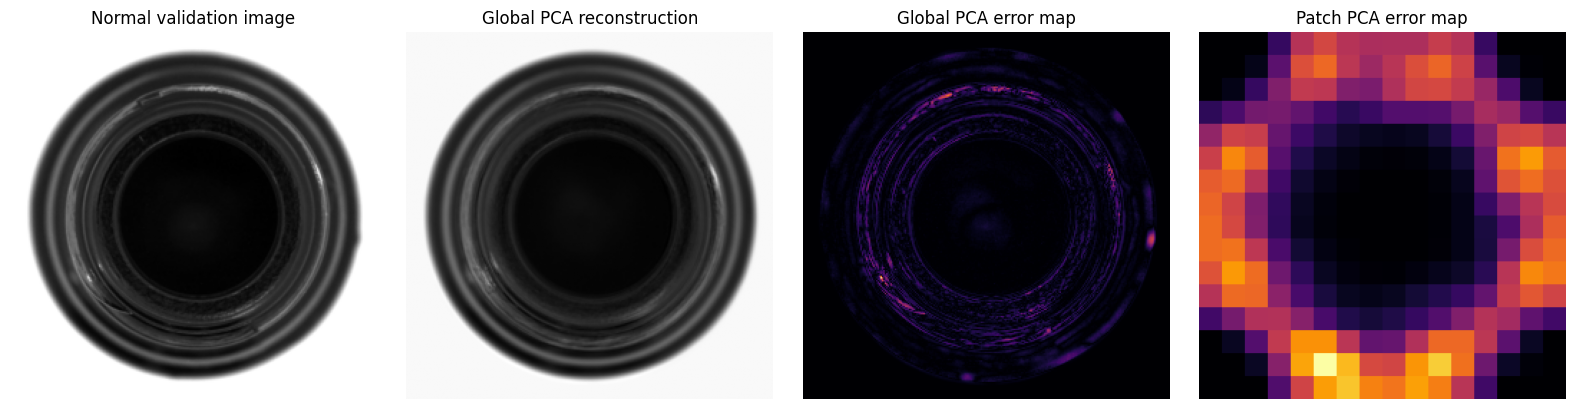

In [21]:
sample = val_ds[0]
image = sample['image'].unsqueeze(0)
original = image[0, 0].numpy()

g_recon = global_model.reconstruct(image)[0, 0]
g_map = global_model.anomaly_map(image)[0]
p_map = patch_model.anomaly_map(image)[0]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(original, cmap='gray')
axes[0].set_title('Normal validation image')
axes[1].imshow(g_recon, cmap='gray')
axes[1].set_title('Global PCA reconstruction')
axes[2].imshow(g_map, cmap='inferno')
axes[2].set_title('Global PCA error map')
axes[3].imshow(p_map, cmap='inferno')
axes[3].set_title('Patch PCA error map')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 10. Save fitted models and experiment metadata

Save outputs outside the raw dataset. Record category, preprocessing, component settings and patch geometry so results are reproducible.

In [22]:
OUT = Path('experiments/pca')
OUT.mkdir(parents=True, exist_ok=True)
global_path = OUT / f'{CATEGORY}_global_pca.npz'
patch_path = OUT / f'{CATEGORY}_patch_pca.npz'
global_model.save(global_path)
patch_model.save(patch_path)
print("Saved:", global_path)
print("Saved:", patch_path)

Saved: experiments/pca/bottle_global_pca.npz
Saved: experiments/pca/bottle_patch_pca.npz


## 11. Next experiments

1. Compare variance targets (for example 0.80, 0.90, 0.95, 0.99) using validation data only.
2. Compare patch sizes / strides without changing the held-out test split.
3. Evaluate image AUROC and pixel AUROC / AP on the official test set only after choices are frozen.
4. Compare global versus patch-wise localization visually and quantitatively.
5. Document failure cases: small defects, texture variation, alignment/position variation and reconstruction of anomalous regions.

**Important:** This notebook is an initial implementation and experiment scaffold. Run all cells in Colab and inspect the outputs before treating results as validated.

## 12. Evaluation on validation-good and official test split

We keep the component setting fixed at the current 95% explained-variance baseline. The validation split contains normal images only, so it is used to set an image-level threshold at a **5% validation false-positive rate** for each detector. No test labels or masks are used to set thresholds.

The official test split is used once for final metrics:
- Image AUROC (image score = maximum anomaly-map value)
- Pixel AUROC and pixel average precision (AP)
- AUPRO (per-region overlap, integrated up to 30% false-positive rate)
- Image-level precision, recall and F1 at the validation-derived threshold

AUPRO uses connected components of the ground-truth defect masks.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    precision_score, recall_score, f1_score
)
from scipy.ndimage import label as connected_components

# Thresholds are calibrated ONLY on normal validation images.
VALIDATION_FPR = 0.05
AUPRO_MAX_FPR = 0.30


def collect_maps(dataset, model, method_name):
    """Return image labels/scores, pixel masks and anomaly maps."""
    image_labels, image_scores, masks, maps = [], [], [], []
    for idx in range(len(dataset)):
        item = dataset[idx]
        x = item["image"].unsqueeze(0)
        if method_name == "global":
            amap = model.anomaly_map(x)[0]
        elif method_name == "patch":
            amap = model.anomaly_map(x)[0]
        else:
            raise ValueError("method_name must be 'global' or 'patch'")

        amap = np.asarray(amap, dtype=np.float32)
        mask = item["mask"].squeeze(0).cpu().numpy().astype(np.uint8)
        image_labels.append(int(item["label"]))
        image_scores.append(float(np.max(amap)))
        masks.append(mask)
        maps.append(amap)
    return (
        np.asarray(image_labels, dtype=np.uint8),
        np.asarray(image_scores, dtype=np.float64),
        np.stack(masks).astype(np.uint8),
        np.stack(maps).astype(np.float32),
    )


def aupro_score(masks, anomaly_maps, max_fpr=0.30, n_thresholds=200):
    """Approximate AUPRO by integrating mean region overlap vs pixel FPR."""
    masks = np.asarray(masks).astype(bool)
    scores = np.asarray(anomaly_maps, dtype=np.float64)
    if masks.shape != scores.shape:
        raise ValueError("Masks and anomaly maps must have identical shapes.")

    region_labels = []
    total_negative = int((~masks).sum())
    for mask in masks:
        labels, n_regions = connected_components(mask)
        for region_id in range(1, n_regions + 1):
            region = labels == region_id
            if region.any():
                region_labels.append(region)

    if not region_labels or total_negative == 0:
        return float("nan")

    # Quantile thresholds provide a stable, bounded-size approximation.
    thresholds = np.unique(np.quantile(scores, np.linspace(0.0, 1.0, n_thresholds)))
    fprs, pros = [0.0], [0.0]
    for threshold in thresholds:
        predicted = scores >= threshold
        fpr = float((predicted & ~masks).sum() / total_negative)
        if fpr > max_fpr:
            continue
        pro = float(np.mean([
            (predicted & region).sum() / region.sum()
            for region in region_labels
        ]))
        fprs.append(fpr)
        pros.append(pro)

    fprs.append(float(max_fpr))
    pros.append(pros[-1])
    order = np.argsort(fprs)
    x = np.asarray(fprs)[order]
    y = np.asarray(pros)[order]
    # Collapse repeated FPR coordinates by keeping their maximum PRO.
    unique_x = np.unique(x)
    unique_y = np.asarray([y[x == value].max() for value in unique_x])
    return float(np.trapz(unique_y, unique_x) / max_fpr)


def evaluate_detector(name, model):
    # Validation split is normal-only. Its image-score distribution sets
    # a threshold corresponding to the chosen validation-good FPR.
    val_labels, val_scores, _, _ = collect_maps(val_ds, model, name)
    if np.any(val_labels != 0):
        raise RuntimeError("Validation split must contain only normal images.")
    threshold = float(np.quantile(val_scores, 1.0 - VALIDATION_FPR, method="higher"))

    # The official test split is used only after threshold calibration.
    test_labels, test_scores, test_masks, test_maps = collect_maps(test_ds, model, name)
    if np.unique(test_labels).size < 2:
        raise RuntimeError("Test split must contain both good and anomalous images.")

    pred_labels = (test_scores >= threshold).astype(np.uint8)
    flat_masks = test_masks.ravel()
    flat_maps = test_maps.ravel()

    return {
        "detector": name,
        "threshold_val_good_5pct_fpr": threshold,
        "validation_good_images": int(len(val_scores)),
        "test_images": int(len(test_labels)),
        "test_anomalous_images": int(test_labels.sum()),
        "image_auroc": float(roc_auc_score(test_labels, test_scores)),
        "pixel_auroc": float(roc_auc_score(flat_masks, flat_maps)),
        "pixel_ap": float(average_precision_score(flat_masks, flat_maps)),
        "aupro_30pct_fpr": aupro_score(test_masks, test_maps, max_fpr=AUPRO_MAX_FPR),
        "image_precision_at_val_threshold": float(precision_score(test_labels, pred_labels, zero_division=0)),
        "image_recall_at_val_threshold": float(recall_score(test_labels, pred_labels, zero_division=0)),
        "image_f1_at_val_threshold": float(f1_score(test_labels, pred_labels, zero_division=0)),
        "validation_fpr_target": VALIDATION_FPR,
    }


evaluation_rows = [
    evaluate_detector("Global PCA", global_model),
    evaluate_detector("Patch-wise PCA", patch_model),
]
evaluation_df = pd.DataFrame(evaluation_rows)
display(evaluation_df.round(4))

# Save per-category result table outside the raw dataset.
results_dir = Path("results/tables")
results_dir.mkdir(parents=True, exist_ok=True)
evaluation_csv = results_dir / f"{CATEGORY}_pca_metrics.csv"
evaluation_df.to_csv(evaluation_csv, index=False)
print("Saved evaluation table:", evaluation_csv)

### Interpretation and limitations

- AUROC and AP are ranking metrics; they do not depend on the chosen threshold.
- The image threshold is calibrated using normal validation images only, at the selected 5% false-positive target.
- Pixel metrics compare each test pixel's score with its ground-truth mask.
- AUPRO is approximated using 200 score quantiles and connected mask regions; record this approximation in the report.
- These results cover the selected category ( `CATEGORY`) only. Repeat the same protocol for all 15 categories before making dataset-wide claims.
- Do not tune the 95% component setting using test results. Any change must be selected using validation data, then evaluated once on test.